# ORF 455: Energy and Commodity Markets PSET 2

## Problem 3 

- a) Plot the first 26 contracts on several dates. Compare the two commodities. Do
you see repeating peaks or troughs? (done)
- b) The natural gas curves show a yearly seasonal pattern. Write the code to remove
this pattern from the curves. Explain your method and plot an example before
and after adjustment. Leave copper unchanged. Use the adjusted natural gas
curves and original copper curves in the remaining parts.
- c) Using the first 12 contracts, classify each day’s curve as contango, backwardation,
humped, or another shape you choose. Explain your rules. Report the percentage
of days in each category and plot these percentages by year.
- d) Divide each first-12-contract curve by its first-contract price. Regress the normal-
ized prices on contract position, including an intercept. Plot the estimated daily
slope for both commodities.
- e) For each commodity, find two days with similar regression slopes but different
curve shapes. Plot the two normalized curves together. What does the slope
miss? Suggest one additional measure that distinguishes the curves.
- f) Define a measure of the change between normalized curves on consecutive available
trading days. For each commodity, find the largest daily change and plot the
curves before and after. Describe what changed. Did the shape category change
too?

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_excel(r"/Users/leenboualia/Downloads/fcurve_data-1.xlsx")

#print(df.head())

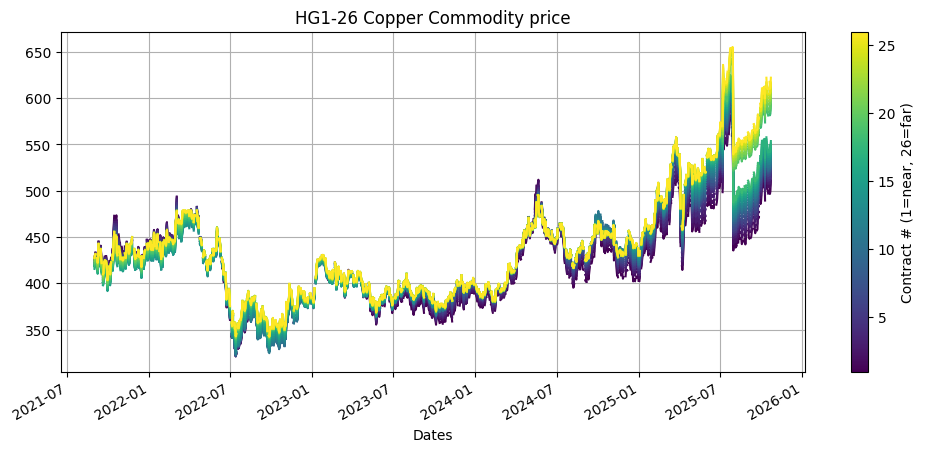

In [47]:
import matplotlib.pyplot as plt
df.dropna()
cols = [c for c in df.columns if c != 'Dates']
# used claude to help make the color a gradient (ask TAs)
ax = df.plot(x='Dates', y=cols, cmap='viridis', 
             title='HG1-26 Copper Commodity price', figsize=(12,5), legend=False, grid=True)

sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(1, len(cols)))
plt.colorbar(sm, ax=ax, label='Contract # (1=near, 26=far)')

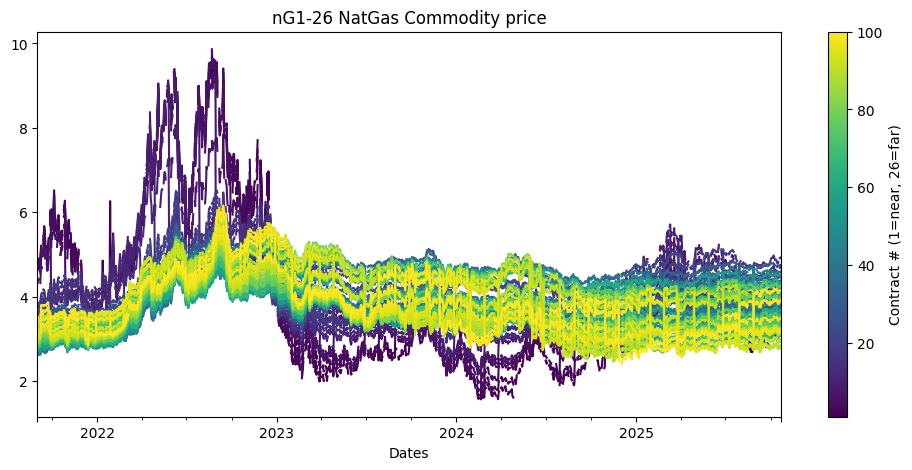

In [48]:
df = pd.read_excel(r"/Users/leenboualia/Downloads/fcurve_data-1.xlsx", sheet_name='NG')
df.dropna()
#df.dropna()
import matplotlib.pyplot as plt

cols = [c for c in df.columns if c != 'Dates']
# used claude to help make the color a gradient (ask TAs)
ax = df.plot(x='Dates', y=cols, cmap='viridis', 
             title='nG1-26 NatGas Commodity price', figsize=(12,5), legend=False)

sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(1, len(cols)))
plt.colorbar(sm, ax=ax, label='Contract # (1=near, 26=far)')

### a)

a) The main difference between natural gas and copper is that nat gas has a far-term stability in futures prices whereas copper's far term prices exhibit more volatility and move relatively faster as a consequence of the near term price movements. Additionally, there ar more trade-able Nat gas contrats with incremental maturity (100) relative to copper (26). The patterns of ackwardation and contango are inverted between the two commodities, i.e longre dated contarcts for copper are more volatile than longer dated contracts for nat gas. 
### Copper
- repeating peaks or troughs: peaks in and around July followed by a subsequent fall.
- Significant/standalone peaks: March 2025 and February 2026 followed by downfall (likely caused correlated with nickel squeeze as discussed in lecture)
- There is a divergence between the prices around July 2027, where the the far termed contracts are rading singificantly higher than the near-term ones. We move frombackwardation to contango inin 2022 and this pattern persists until 2024, then we return to contango and divergence. 
- A reversion between the prices of the contracts occurs starting Q1 2022, where the far-term contracts are trading higher than the near-term ones. This reverses duringg the peak in 2024 and returns when the divergence occurs in 2025 due to the war and clsoure of the Hormus straight.
- prices decrease in the summer, probably due to less need for insulation
### Natural Gas
- peaks occur in higher frequency and noise in 2022, spread between near and far term contacts widen
- 2022 shock driven by RussiaUkraine war and threat of cutting gas off Europe, Russia's largest nat gas importer. 
- Longer dated contracts move significantly slower than shorter dated contracts and are less voaltile
- yearly seasonal pattern: prices decrease in March- May periods when weather is mild, increases in summer when cooling demand is high, similarlY winter prices reach peak volatility due to high insulation and heatind demand fro eUROPE
- Natural gas shows repeating peaks about 12 contracts apart, peaks are the winter delivery months (Dec–Feb) and the troughs are the spring and autumn shoulder months

### b)
- In order to remov the trends, we should find the delivery months of the contracts and how they are spaced from each other. For example, on a date with month k delivery happens m+k later

- At these diff times, we want to take the rolling average of the contracts across these term structures. We take the logarith m of this amount in order to capture the percent difference instead of the dollar difference. 
- To capture the seasonal factors we average tthe gaps by month, this will redice the choppy-ness of the inter-matruity price for each contract

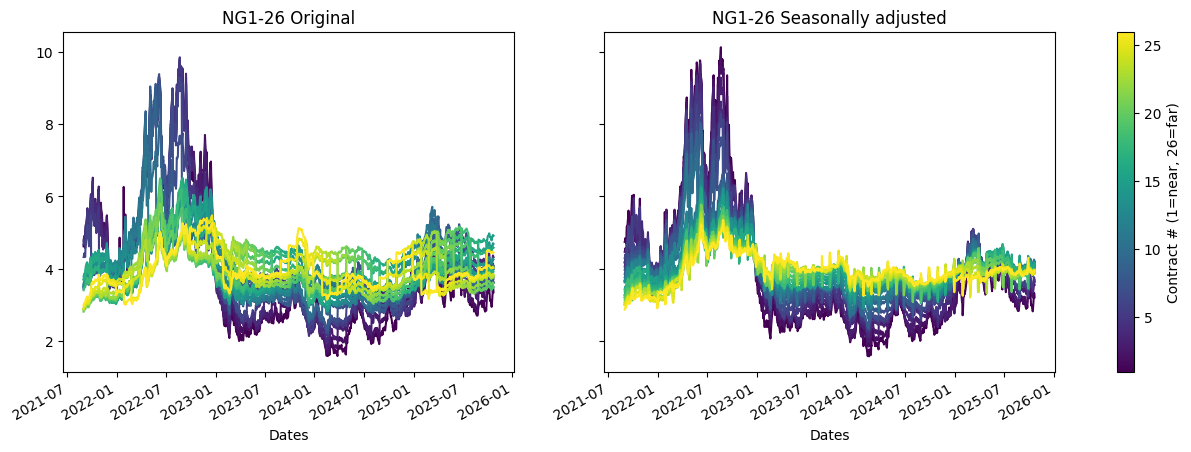

In [55]:
ng = df.set_index('Dates').iloc[:, :26].dropna(how='all')
#print(ng)
ng.columns = range(1, 27)

# delivery month of each contract (0 = Dec, 1 = Jan, ..., 11 = Nov)
month = (ng.index.month.values[:, None] + ng.columns.values) % 12

# seasonality = log price minus its 12-contract moving average
logF = np.log(ng)
dev = logF - logF.T.rolling(12, center=True).mean().T
s = pd.Series(dev.values.ravel()).groupby(month.ravel()).mean()
s = s - s.mean()

ng_adj = ng * np.exp(-s.values[month])

d = ng.dropna().index[-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

ng.plot(ax=axes[0], cmap='viridis', legend=False, title='NG1-26 Original')
ng_adj.plot(ax=axes[1], cmap='viridis', legend=False, title='NG1-26 Seasonally adjusted')

sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(1, 26))
plt.colorbar(sm, ax=axes, label='Contract # (1=near, 26=far)')
plt.show()

### c) Classify each contract as backwardation or contango
- Bakwardation: future's price is less than spot, forward curve is downwards sloping// he curve slopes down, meaning supply is tight now and the convenience yield is high --> F1>F12
- Contango: future's price is above spot, forward curve is upwards sloping\\ the market expects higher prices or storage is plentiful --> F12>F1
- Humped:some middle contract is more than 1% above both ends. The curve rises and then fall
- Dipped:some middle contract is more than 1% below both ends. The curve falls and then rises
- we use a cross-voer cross under to see the points of inflection where we go frm baclwardation to contago and vice versa. we compare 12 contracts on each given day and chech whether the front F1 is higher or lower than theback F2 and we account for th ehighest ad lwoest of the middle contracts to help us determine if we are in backwardation or contango. is the difference between F1 and F12 is greater than |1%| then we consider it contango if F12> F1 and backwardation if F12<F1 

Natural gas (adj.)
Contango         51.6
Humped           24.3
Backwardation    15.2
Dipped            8.9
Name: proportion, dtype: float64 

Copper
Contango         54.6
Flat             23.2
Backwardation    18.8
Dipped            2.1
Humped            1.3
Name: proportion, dtype: float64 



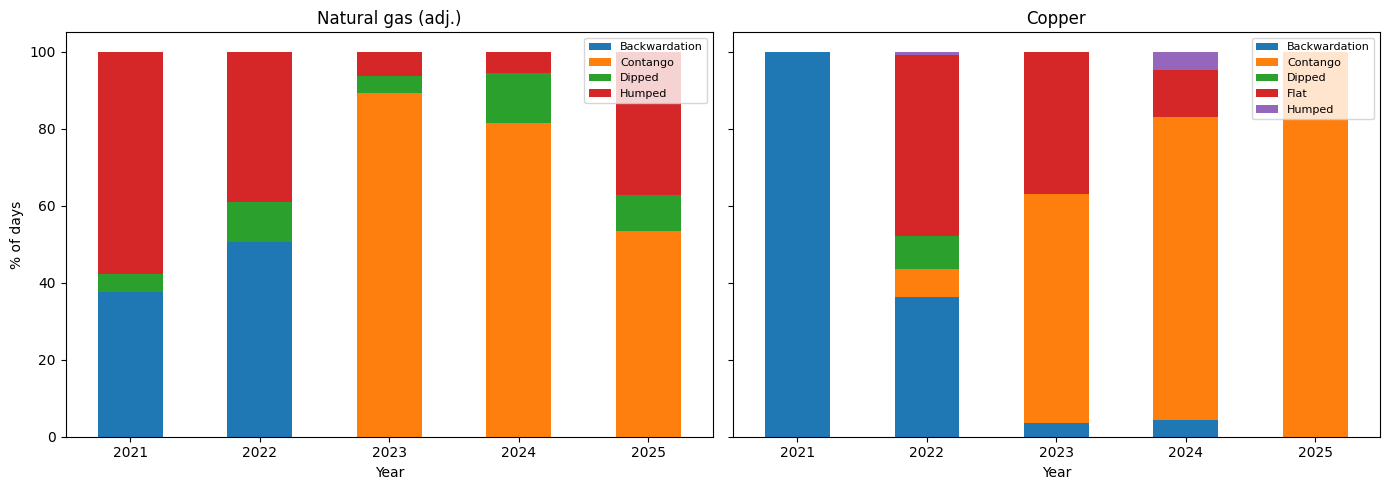

In [58]:
cu = pd.read_excel(r"/Users/leenboualia/Downloads/fcurve_data-1.xlsx", sheet_name='HG')
cu = cu.set_index('Dates').iloc[:, :26].dropna(how='all')
cu.columns = range(1, 27)

def classify(df, tol=0.01):
    F = df.iloc[:, :12].dropna()                 
    f1, f12 = F[1], F[12]                      
    hi = F.iloc[:, 1:11].max(axis=1)          
    lo = F.iloc[:, 1:11].min(axis=1)           
    shape = np.select(
        [hi > np.maximum(f1, f12) * (1 + tol),  
         lo < np.minimum(f1, f12) * (1 - tol),   
         f12 > f1 * (1 + tol),                   
         f1 > f12 * (1 + tol)],                 
        ['Humped', 'Dipped', 'Contango', 'Backwardation'],
        default='Flat')
    return pd.Series(shape, index=F.index)

shapes = {'Natural gas (adj.)': classify(ng_adj), 'Copper': classify(cu)}

# overall percentages
for name, s in shapes.items():
    print(name); print((s.value_counts(normalize=True) * 100).round(1), '\n')

# percentages by year
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, s) in zip(axes, shapes.items()):
    pct = pd.crosstab(s.index.year, s, normalize='index') * 100
    pct.plot(kind='bar', stacked=True, ax=ax, title=name, rot=0)
    ax.set(xlabel='Year', ylabel='% of days')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### d

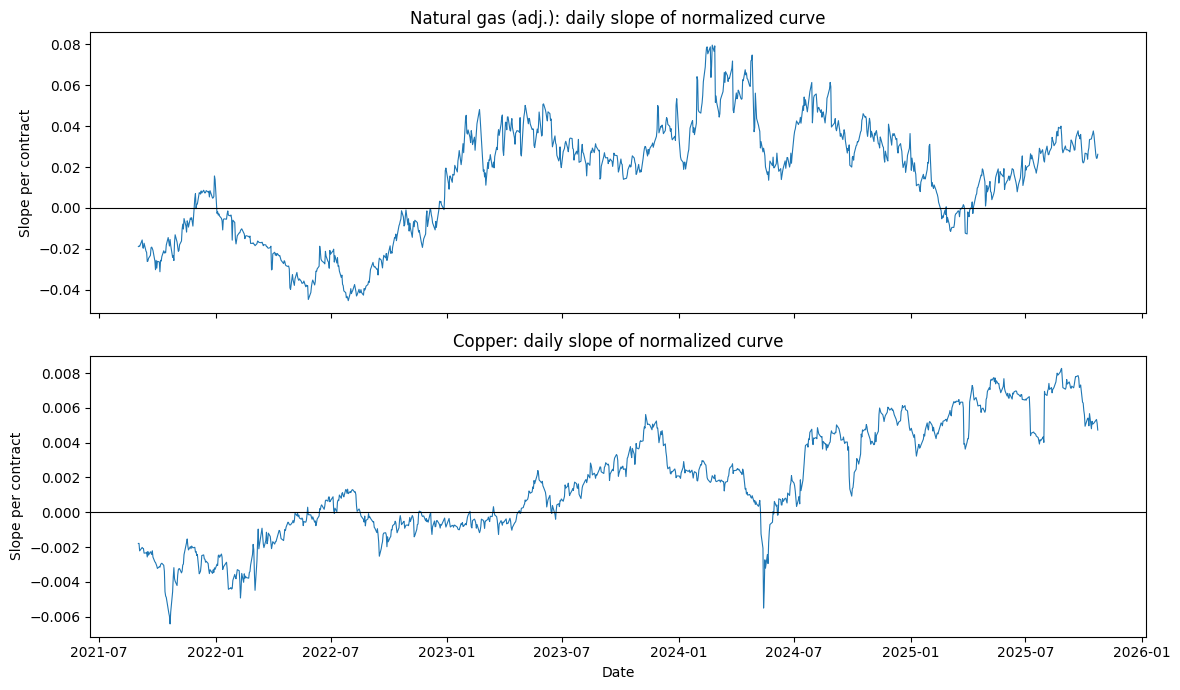

              NG     Copper
count  1043.0000  1043.0000
mean      0.0144     0.0017
std       0.0277     0.0032
min      -0.0453    -0.0064
25%      -0.0082    -0.0006
50%       0.0208     0.0014
75%       0.0348     0.0044
max       0.0796     0.0083


In [59]:
def daily_slope(df):
    F = df.iloc[:, :12].dropna()           
    y = F.div(F[1], axis=0)                
    x = np.arange(1, 13)                    
    xc = x - x.mean()
    return (y * xc).sum(axis=1) / (xc ** 2).sum()   

slope_ng = daily_slope(ng_adj)
slope_cu = daily_slope(cu)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, s, name in [(axes[0], slope_ng, 'Natural gas (adj.)'), (axes[1], slope_cu, 'Copper')]:
    ax.plot(s.index, s.values, lw=0.8)
    ax.axhline(0, color='k', lw=0.8)
    ax.set(title=f'{name}: daily slope of normalized curve', ylabel='Slope per contract')
axes[1].set_xlabel('Date')
plt.tight_layout(); plt.show()

print(pd.DataFrame({'NG': slope_ng.describe(), 'Copper': slope_cu.describe()}).round(4))

### e 
- we know that the match tells us the tilt between the forward and backward looking prices.The slope can tell us whether we ar ein backwardation or contango if it is above or below one, but it can not tell us whetehr the crve is humped or dipped or straight 
- We can fit a quadratic function onto the the price/front price ratio and deduce:
- if the fit is convex this indicates steepening in the back whic indicates that its dipped
- if the fit is a concave function then it is humped and flattening on the back 

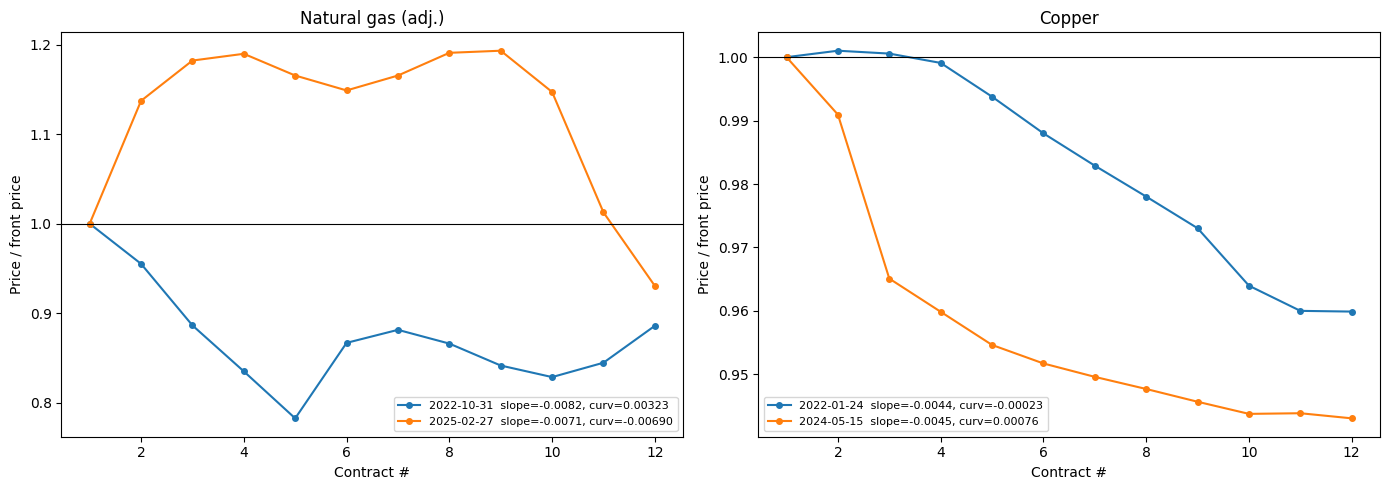

In [60]:
x = np.arange(1, 13)

def normalized(df):
    F = df.iloc[:, :12].dropna()
    return F.div(F[1], axis=0)

def find_pair(Y, tol=0.05):
    b = np.polyfit(x, Y.T.values, 1)[0]           
    c = np.polyfit(x, Y.T.values, 2)[0]            
    same_slope = np.abs(b[:, None] - b[None, :]) < tol * b.std()   
    gap = np.where(same_slope, np.abs(c[:, None] - c[None, :]), -1)
    i, j = np.unravel_index(gap.argmax(), gap.shape)            
    return i, j, b, c

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, df, name in [(axes[0], ng_adj, 'Natural gas (adj.)'), (axes[1], cu, 'Copper')]:
    Y = normalized(df)
    i, j, b, c = find_pair(Y)
    for k in (i, j):
        ax.plot(x, Y.iloc[k], 'o-', ms=4,
                label=f'{Y.index[k].date()}  slope={b[k]:.4f}, curv={c[k]:.5f}')
    ax.axhline(1, color='k', lw=0.8)
    ax.set(title=name, xlabel='Contract #', ylabel='Price / front price')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### f)
- on each day we will compare the normalized curve to the one from the previous day

$$D_t = \sqrt{ \frac{1}{12} \sum_{k} (Y_{t,k} - Y_{t-1,k})^2 } \quad \text{where} \quad Y_{t,k} = \frac{F_{t,k}}{F_{t,1}}$$
- We take the square root of the squared change in order to normalize the curve and pick up the change in the shape
- Category for Natural gas in January 2022 changed from backwardation to humped; curvature switched signs when F1 dropped from 5.56 to 4.12 from Januray 27 and the 28th because Jan 27th is the last day to buy the contracts for february and so there was a switch between one contract to another
- For copper: did not change shapes, but the backwardations steepened since the cirvature increased in April 2025 on the 13h and 14th. This is because 

Natural gas (adj.) 2022-01-27: F1=5.569  F12=3.945  slope=-0.0157  curv=+0.00005  class=Backwardation
Natural gas (adj.) 2022-01-28: F1=4.123  F12=4.016  slope=-0.0060  curv=-0.00649  class=Humped
Natural gas (adj.): largest change D = 0.3302 on 2022-01-28
Top 5 days: ['2022-01-28', '2024-01-30', '2022-01-27', '2024-04-29', '2025-02-03'] 

Copper 2024-05-13: F1=480.450  F12=467.750  slope=-0.0021  curv=+0.00027  class=Backwardation
Copper 2024-05-14: F1=495.350  F12=460.550  slope=-0.0055  curv=+0.00099  class=Backwardation
Copper: largest change D = 0.0371 on 2024-05-14
Top 5 days: ['2024-05-14', '2025-07-31', '2024-05-16', '2025-03-26', '2024-05-10'] 



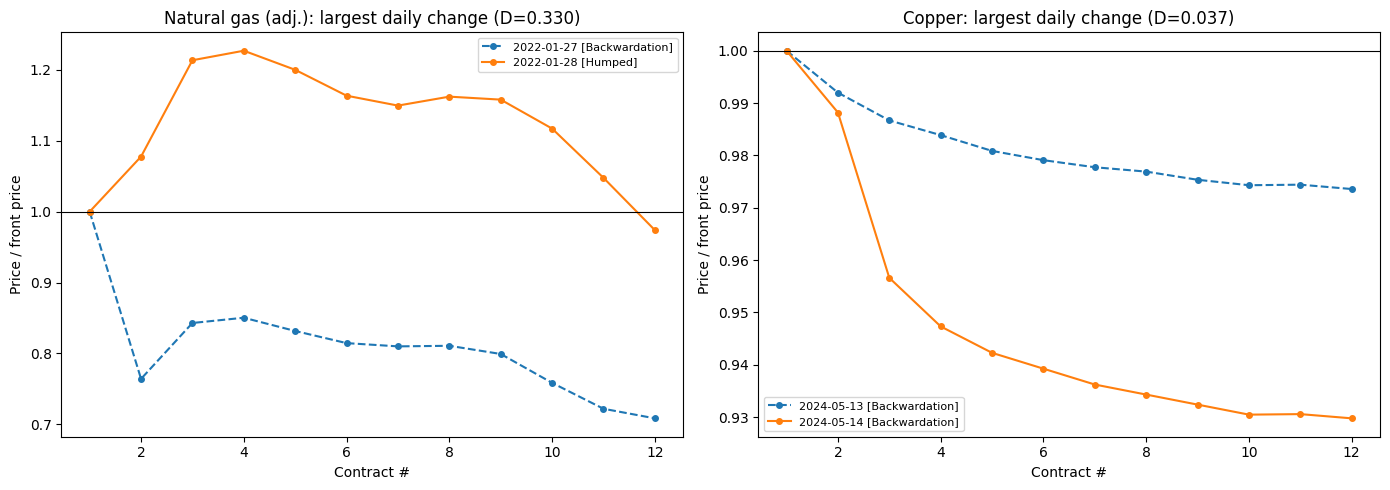

In [63]:
def curve_change(df):
    Y = normalized(df)                                   
    D = np.sqrt(((Y - Y.shift(1)) ** 2).mean(axis=1)).dropna()
    return Y, D

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, df, name in [(axes[0], ng_adj, 'Natural gas (adj.)'), (axes[1], cu, 'Copper')]:
    Y, D = curve_change(df)
    lab = classify(df)
    t = D.idxmax()                                        
    p = Y.index[Y.index.get_loc(t) - 1]                   

    for d, style in [(p, 'o--'), (t, 'o-')]:
        b, c = np.polyfit(x, Y.loc[d], 2)[[1, 0]]
        ax.plot(x, Y.loc[d], style, ms=4, label=f'{d.date()} [{lab[d]}]')
        print(f'{name} {d.date()}: F1={df.loc[d, 1]:.3f}  F12={df.loc[d, 12]:.3f}  '
              f'slope={np.polyfit(x, Y.loc[d], 1)[0]:+.4f}  curv={c:+.5f}  class={lab[d]}')
    print(f'{name}: largest change D = {D.max():.4f} on {t.date()}')
    print('Top 5 days:', [str(d.date()) for d in D.nlargest(5).index], '\n')

    ax.axhline(1, color='k', lw=0.8)
    ax.set(title=f'{name}: largest daily change (D={D.max():.3f})',
           xlabel='Contract #', ylabel='Price / front price')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()